In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Load dataset
df = pd.read_csv("../data/raw/customer_churn.csv")

# Display first 5 records
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# Dataset dimensions
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Dataset information
df.info()


Rows: 7043
Columns: 21
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-nul

In [4]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
print("Total Columns:", len(df.columns))

for col in df.columns:
    print(col)

Total Columns: 21
customerID
gender
SeniorCitizen
Partner
Dependents
tenure
PhoneService
MultipleLines
InternetService
OnlineSecurity
OnlineBackup
DeviceProtection
TechSupport
StreamingTV
StreamingMovies
Contract
PaperlessBilling
PaymentMethod
MonthlyCharges
TotalCharges
Churn


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [7]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check blank spaces in TotalCharges
print("\nBlank TotalCharges:")
print((df["TotalCharges"].str.strip() == "").sum())

# Check duplicate records
print("\nDuplicate Rows:", df.duplicated().sum())

Missing Values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Blank TotalCharges:
11

Duplicate Rows: 0


In [8]:
# Convert TotalCharges into numeric format
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].str.strip(),
    errors="coerce"
)

# Check missing values again
print("Missing TotalCharges:", df["TotalCharges"].isnull().sum())

# Display rows with missing TotalCharges
df[df["TotalCharges"].isnull()]

Missing TotalCharges: 11


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [9]:
# Fill missing TotalCharges with 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# Verify missing values
print("Missing values after cleaning:")
print(df.isnull().sum().sum())

# Check TotalCharges data type
print("\nTotalCharges Data Type:", df["TotalCharges"].dtype)

# Verify cleaned records
print("\nTotalCharges for zero-tenure customers:")
print(df.loc[df["tenure"] == 0, ["tenure", "MonthlyCharges", "TotalCharges"]].head(12))

Missing values after cleaning:
0

TotalCharges Data Type: float64

TotalCharges for zero-tenure customers:
      tenure  MonthlyCharges  TotalCharges
488        0           52.55           0.0
753        0           20.25           0.0
936        0           80.85           0.0
1082       0           25.75           0.0
1340       0           56.05           0.0
3331       0           19.85           0.0
3826       0           25.35           0.0
4380       0           20.00           0.0
5218       0           19.70           0.0
6670       0           73.35           0.0
6754       0           61.90           0.0


In [10]:
# Identify numerical columns
numerical_cols = df.select_dtypes(include=["int64", "float64"]).columns.tolist()

# Identify categorical columns
categorical_cols = df.select_dtypes(include=["object", "str"]).columns.tolist()

print("Numerical Columns:")
print(numerical_cols)

print("\nCategorical Columns:")
print(categorical_cols)

print("\nNumerical Column Count:", len(numerical_cols))
print("Categorical Column Count:", len(categorical_cols))

Numerical Columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Columns:
['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn']

Numerical Column Count: 4
Categorical Column Count: 17


In [11]:
# Count customers in each churn category
churn_counts = df["Churn"].value_counts()

print("Customer Churn Count:")
print(churn_counts)

# Calculate percentage
churn_percentage = df["Churn"].value_counts(normalize=True) * 100

print("\nCustomer Churn Percentage:")
print(churn_percentage.round(2))

Customer Churn Count:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Customer Churn Percentage:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


In [13]:
# Analyze churn percentage by contract type
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print(contract_churn.round(2))

Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83


# Customer Churn Distribution


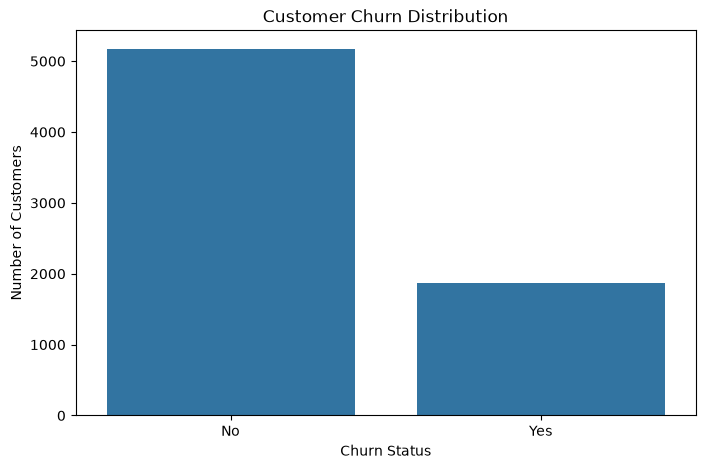

In [29]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

plt.savefig(
    "../reports/figures/churn_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Contract Type vs Churn Analysis

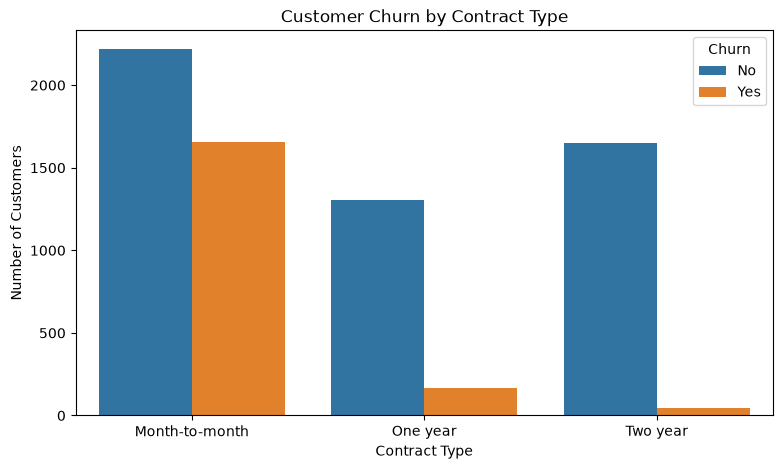

In [14]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Contract",
    hue="Churn"
)

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.legend(title="Churn")

plt.savefig(
    "../reports/figures/churn_by_contract.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [15]:
print(
    df.groupby("Churn")["tenure"]
    .agg(["mean", "median", "min", "max"])
    .round(2)
)

        mean  median  min  max
Churn                         
No     37.57    38.0    0   72
Yes    17.98    10.0    1   72


In [16]:
# Average monthly charges by churn status

print(
    df.groupby("Churn")["MonthlyCharges"]
    .agg(["mean", "median"])
    .round(2)
)

        mean  median
Churn               
No     61.27   64.43
Yes    74.44   79.65


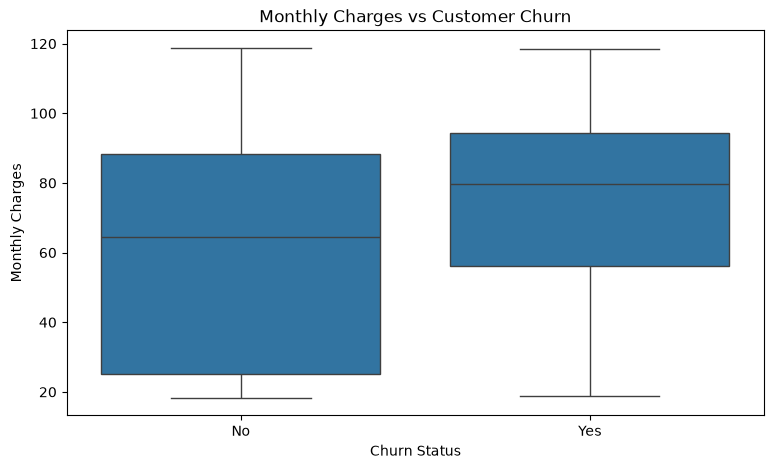

In [17]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges vs Customer Churn")
plt.xlabel("Churn Status")
plt.ylabel("Monthly Charges")

plt.savefig(
    "../reports/figures/monthly_charges_vs_churn.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [18]:
# Churn percentage by Internet Service

internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

print(internet_churn.round(2))

Churn               No    Yes
InternetService              
DSL              81.04  18.96
Fiber optic      58.11  41.89
No               92.60   7.40


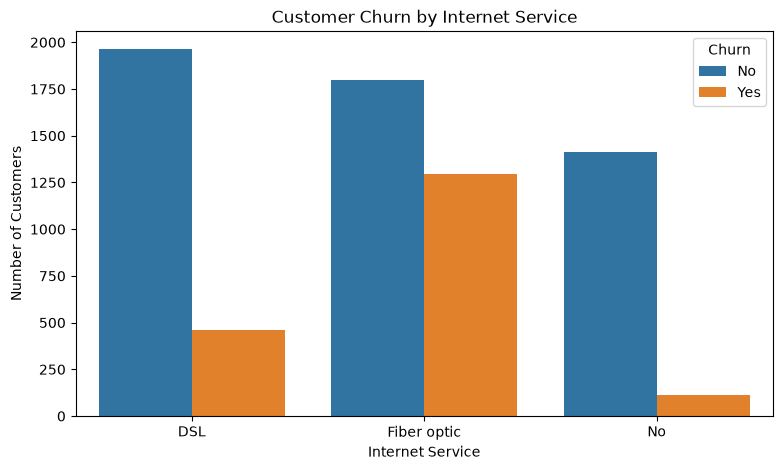

In [19]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="InternetService",
    hue="Churn"
)

plt.title("Customer Churn by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")
plt.legend(title="Churn")

plt.savefig(
    "../reports/figures/churn_by_internet_service.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [20]:
# Churn percentage by payment method

payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

print(payment_churn.round(2))

Churn                         No    Yes
PaymentMethod                          
Bank transfer (automatic)  83.29  16.71
Credit card (automatic)    84.76  15.24
Electronic check           54.71  45.29
Mailed check               80.89  19.11


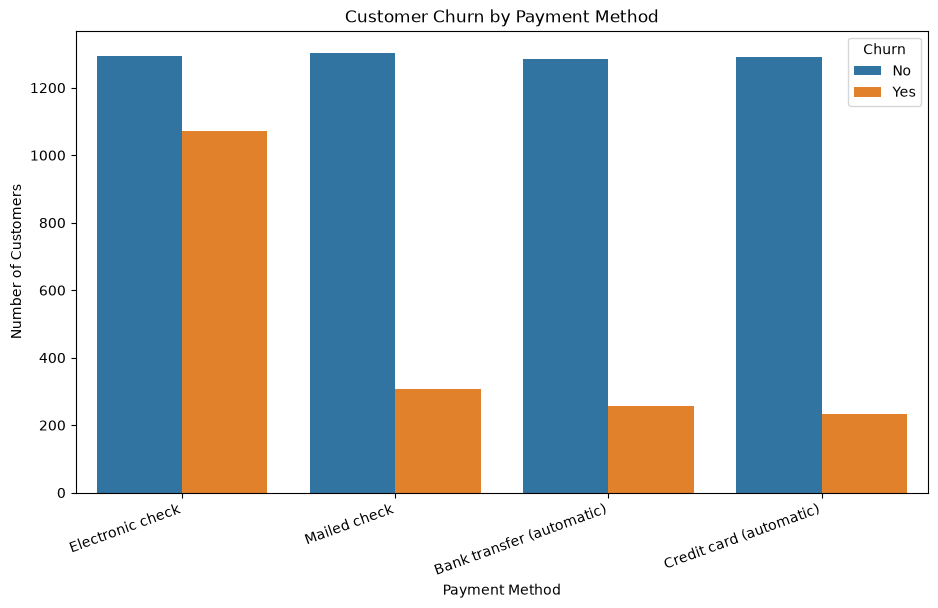

In [21]:
plt.figure(figsize=(11, 6))

sns.countplot(
    data=df,
    x="PaymentMethod",
    hue="Churn"
)

plt.title("Customer Churn by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20, ha="right")
plt.legend(title="Churn")

plt.savefig(
    "../reports/figures/churn_by_payment_method.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [22]:
# Online Security vs Churn
security_churn = pd.crosstab(
    df["OnlineSecurity"],
    df["Churn"],
    normalize="index"
) * 100

print("Online Security vs Churn:")
print(security_churn.round(2))

# Tech Support vs Churn
support_churn = pd.crosstab(
    df["TechSupport"],
    df["Churn"],
    normalize="index"
) * 100

print("\nTech Support vs Churn:")
print(support_churn.round(2))

Online Security vs Churn:
Churn                   No    Yes
OnlineSecurity                   
No                   58.23  41.77
No internet service  92.60   7.40
Yes                  85.39  14.61

Tech Support vs Churn:
Churn                   No    Yes
TechSupport                      
No                   58.36  41.64
No internet service  92.60   7.40
Yes                  84.83  15.17


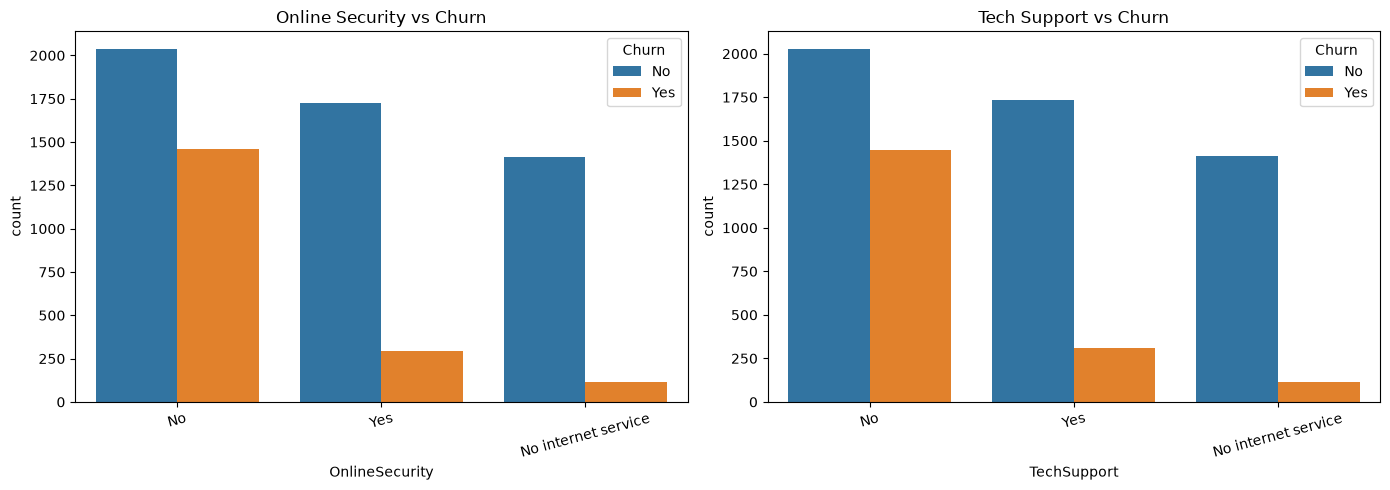

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(
    data=df,
    x="OnlineSecurity",
    hue="Churn",
    ax=axes[0]
)

axes[0].set_title("Online Security vs Churn")
axes[0].tick_params(axis="x", rotation=15)

sns.countplot(
    data=df,
    x="TechSupport",
    hue="Churn",
    ax=axes[1]
)

axes[1].set_title("Tech Support vs Churn")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()

plt.savefig(
    "../reports/figures/service_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# tenure vs churn

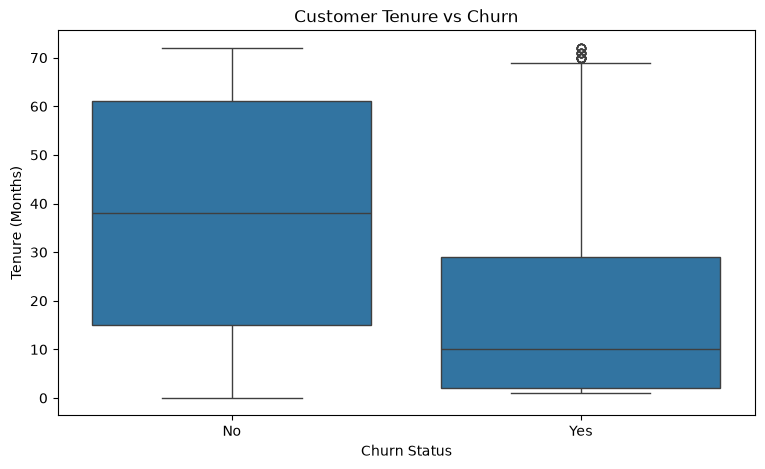

In [30]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure"
)

plt.title("Customer Tenure vs Churn")
plt.xlabel("Churn Status")
plt.ylabel("Tenure (Months)")

plt.savefig(
    "../reports/figures/tenure_vs_churn.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [24]:
# Customer Churn EDA Summary

print("========== CUSTOMER CHURN EDA SUMMARY ==========")

print("\n1. Overall Churn Rate:")
print(round((df["Churn"] == "Yes").mean() * 100, 2), "%")

print("\n2. Highest Risk Contract:")
print(contract_churn["Yes"].idxmax(),
      "-", round(contract_churn["Yes"].max(), 2), "%")

print("\n3. Highest Risk Internet Service:")
print(internet_churn["Yes"].idxmax(),
      "-", round(internet_churn["Yes"].max(), 2), "%")

print("\n4. Highest Risk Payment Method:")
print(payment_churn["Yes"].idxmax(),
      "-", round(payment_churn["Yes"].max(), 2), "%")

print("\n5. Average Tenure:")
print(df.groupby("Churn")["tenure"].mean().round(2))

print("\n6. Average Monthly Charges:")
print(df.groupby("Churn")["MonthlyCharges"].mean().round(2))

print("\n7. Online Security:")
print(security_churn["Yes"].round(2))

print("\n8. Tech Support:")
print(support_churn["Yes"].round(2))


========== CUSTOMER CHURN EDA SUMMARY ==========

1. Overall Churn Rate:
26.54 %

2. Highest Risk Contract:
Month-to-month - 42.71 %

3. Highest Risk Internet Service:
Fiber optic - 41.89 %

4. Highest Risk Payment Method:
Electronic check - 45.29 %

5. Average Tenure:
Churn
No     37.57
Yes    17.98
Name: tenure, dtype: float64

6. Average Monthly Charges:
Churn
No     61.27
Yes    74.44
Name: MonthlyCharges, dtype: float64

7. Online Security:
OnlineSecurity
No                     41.77
No internet service     7.40
Yes                    14.61
Name: Yes, dtype: float64

8. Tech Support:
TechSupport
No                     41.64
No internet service     7.40
Yes                    15.17
Name: Yes, dtype: float64


In [25]:
# Create a copy for machine learning
ml_df = df.copy()

# Remove customer ID
ml_df = ml_df.drop("customerID", axis=1)

# Separate features and target
X = ml_df.drop("Churn", axis=1)
y = ml_df["Churn"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())

Features Shape: (7043, 19)
Target Shape: (7043,)

Target Distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [26]:
# Convert target labels into numeric values

y = y.map({
    "No": 0,
    "Yes": 1
})

print("Target after encoding:")
print(y.value_counts())

print("\nTarget Data Type:", y.dtype)

Target after encoding:
Churn
0    5174
1    1869
Name: count, dtype: int64

Target Data Type: int64


In [27]:
# Identify categorical and numerical features

categorical_features = X.select_dtypes(
    include=["object", "str"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Categorical Features:")
print(categorical_features)

print("\nNumerical Features:")
print(numerical_features)

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


In [28]:
import os

folder = "../reports/figures"

print("Saved Graph Files:")

for file in os.listdir(folder):
    if file.endswith(".png"):
        print(file)

print("\nTotal Saved Graphs:",
      len([f for f in os.listdir(folder) if f.endswith(".png")]))

Saved Graph Files:
churn_by_contract.png
churn_by_internet_service.png
churn_by_payment_method.png
monthly_charges_vs_churn.png
service_analysis.png

Total Saved Graphs: 5


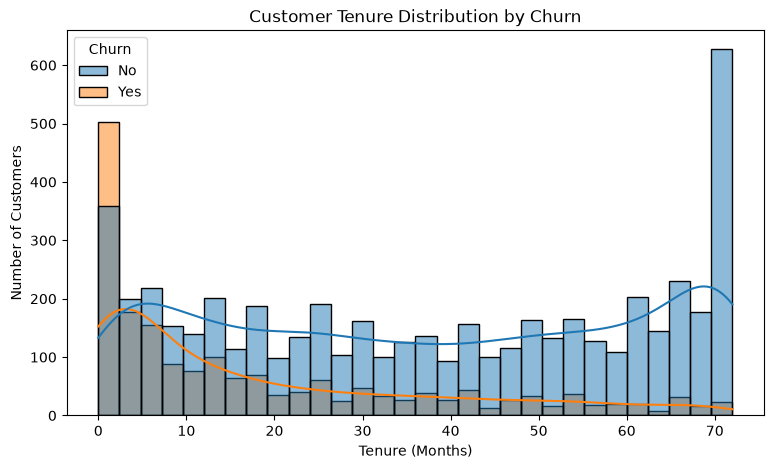

In [31]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="tenure",
    hue="Churn",
    bins=30,
    kde=True,
    multiple="layer"
)

plt.title("Customer Tenure Distribution by Churn")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")

plt.savefig(
    "../reports/figures/tenure_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [32]:
import os

folder = "../reports/figures"

files = [
    f for f in os.listdir(folder)
    if f.endswith(".png")
]

for file in sorted(files):
    print(file)

print("\nTotal Saved Graph Files:", len(files))

churn_by_contract.png
churn_by_internet_service.png
churn_by_payment_method.png
churn_distribution.png
monthly_charges_vs_churn.png
service_analysis.png
tenure_distribution.png
tenure_vs_churn.png

Total Saved Graph Files: 8


In [33]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True))

ModuleNotFoundError: No module named 'sklearn'

In [34]:
import sys

print("Python Executable:", sys.executable)
print("Python Version:", sys.version)



Python Executable: c:\Program Files\Python313\python.exe
Python Version: 3.13.13 (tags/v3.13.13:01104ce, Apr  7 2026, 19:25:48) [MSC v.1944 64 bit (AMD64)]


In [1]:
import sys
print(sys.executable)

c:\Users\bhanu\anaconda3\python.exe


In [2]:
import sklearn

print("Scikit-learn Version:", sklearn.__version__)

Scikit-learn Version: 1.9.1


In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True))

NameError: name 'X' is not defined

In [4]:
# Prepare ML dataset
ml_df = df.copy()

# Remove customerID because it is only an identifier
ml_df = ml_df.drop("customerID", axis=1)

# Separate features and target
X = ml_df.drop("Churn", axis=1)
y = ml_df["Churn"].map({"No": 0, "Yes": 1})

print("X Shape:", X.shape)
print("y Shape:", y.shape)
print("\nTarget Distribution:")
print(y.value_counts())

NameError: name 'df' is not defined

In [5]:
import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv("../data/raw/customer_churn.csv")

# Clean TotalCharges
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].str.strip(),
    errors="coerce"
)

df["TotalCharges"] = df["TotalCharges"].fillna(0)

print("Dataset Shape:", df.shape)
print("Missing Values:", df.isnull().sum().sum())
print("\nDataset Loaded Successfully!")

Dataset Shape: (7043, 21)
Missing Values: 0

Dataset Loaded Successfully!


In [6]:
ml_df = df.copy()

# Remove customerID
ml_df = ml_df.drop("customerID", axis=1)

# Separate features and target
X = ml_df.drop("Churn", axis=1)
y = ml_df["Churn"].map({"No": 0, "Yes": 1})

print("X Shape:", X.shape)
print("y Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())

X Shape: (7043, 19)
y Shape: (7043,)

Target Distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True))

Training Data: (5634, 19)
Testing Data: (1409, 19)

Training Target Distribution:
Churn
0    0.734647
1    0.265353
Name: proportion, dtype: float64

Testing Target Distribution:
Churn
0    0.734564
1    0.265436
Name: proportion, dtype: float64


In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Identify numerical and categorical columns
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical Features:", numerical_features)
print("\nCategorical Features:", categorical_features)

Numerical Features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


C:\Users\bhanu\AppData\Local\Temp\ipykernel_12968\2364149153.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numerical preprocessing
numerical_transformer = StandardScaler()

# Categorical preprocessing
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

# Combine both preprocessors
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing Pipeline Created Successfully!")

Preprocessing Pipeline Created Successfully!


In [10]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Create Logistic Regression pipeline
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        ))
    ]
)

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [11]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Make predictions
y_pred = logistic_model.predict(X_test)

# Evaluate model
print("Logistic Regression Model Performance")
print("--------------------------------------")

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Logistic Regression Model Performance
--------------------------------------
Accuracy: 0.7381121362668559
Precision: 0.504302925989673
Recall: 0.7834224598930482
F1 Score: 0.6136125654450262

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1035
           1       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



Confusion Matrix:
[[747 288]
 [ 81 293]]


NameError: name 'plt' is not defined

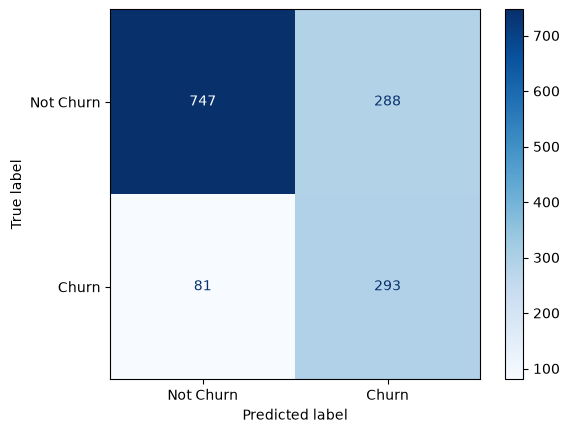

In [13]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# Visualize confusion matrix
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Churn", "Churn"]
)

display.plot(cmap="Blues", values_format="d")

plt.title("Logistic Regression - Confusion Matrix")

plt.savefig(
    "../reports/figures/logistic_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

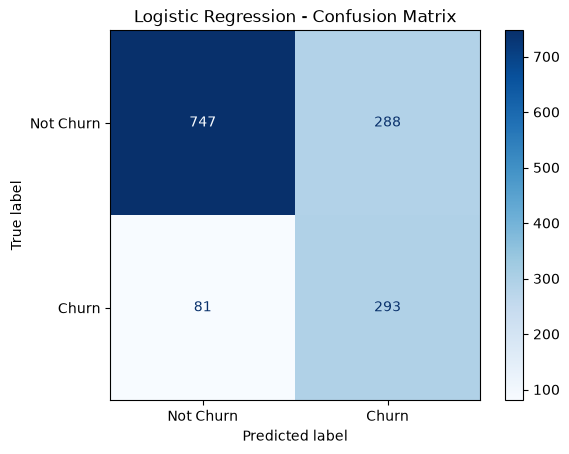

In [14]:
import matplotlib.pyplot as plt

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Churn", "Churn"]
)

display.plot(cmap="Blues", values_format="d")

plt.title("Logistic Regression - Confusion Matrix")

plt.savefig(
    "../reports/figures/logistic_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [15]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Create Random Forest pipeline
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            max_depth=12,
            min_samples_split=5,
            min_samples_leaf=2,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

# Train model
random_forest_model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [16]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Make predictions
rf_pred = random_forest_model.predict(X_test)

# Evaluate model
print("Random Forest Model Performance")
print("--------------------------------")

print("Accuracy:", accuracy_score(y_test, rf_pred))
print("Precision:", precision_score(y_test, rf_pred))
print("Recall:", recall_score(y_test, rf_pred))
print("F1 Score:", f1_score(y_test, rf_pred))

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

Random Forest Model Performance
--------------------------------
Accuracy: 0.7601135557132718
Precision: 0.5347490347490348
Recall: 0.7406417112299465
F1 Score: 0.6210762331838565

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.77      0.82      1035
           1       0.53      0.74      0.62       374

    accuracy                           0.76      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.80      0.76      0.77      1409



Logistic Regression ROC-AUC: 0.8416388953473353
Random Forest ROC-AUC: 0.8372368183109871


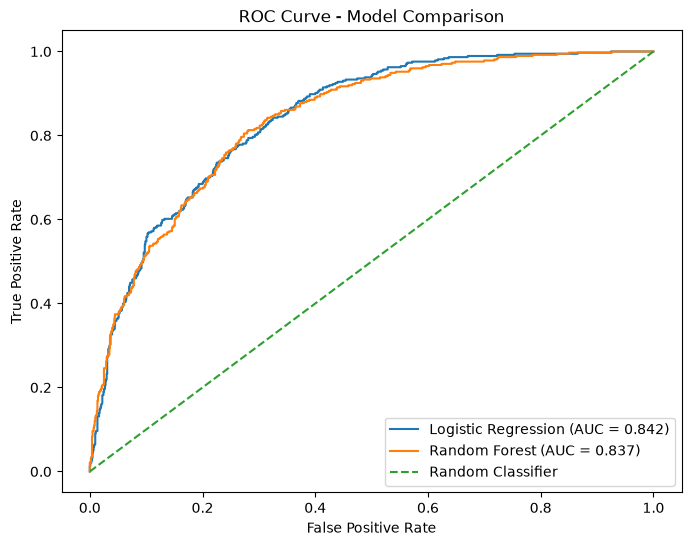

In [17]:
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt

# Get churn probabilities
lr_prob = logistic_model.predict_proba(X_test)[:, 1]
rf_prob = random_forest_model.predict_proba(X_test)[:, 1]

# Calculate ROC-AUC
lr_auc = roc_auc_score(y_test, lr_prob)
rf_auc = roc_auc_score(y_test, rf_prob)

print("Logistic Regression ROC-AUC:", lr_auc)
print("Random Forest ROC-AUC:", rf_auc)

# ROC curves
lr_fpr, lr_tpr, _ = roc_curve(y_test, lr_prob)
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_prob)

plt.figure(figsize=(8, 6))

plt.plot(lr_fpr, lr_tpr, label=f"Logistic Regression (AUC = {lr_auc:.3f})")
plt.plot(rf_fpr, rf_tpr, label=f"Random Forest (AUC = {rf_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Model Comparison")
plt.legend()

plt.savefig(
    "../reports/figures/roc_curve_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [18]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline

xgb_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", XGBClassifier(
            n_estimators=300,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

xgb_model.fit(X_train, y_train)

print("XGBoost Model Trained Successfully!")

XGBoost Model Trained Successfully!


In [19]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    roc_auc_score
)

# Predictions
xgb_pred = xgb_model.predict(X_test)

# Probabilities
xgb_prob = xgb_model.predict_proba(X_test)[:, 1]

# Evaluation
print("XGBoost Model Performance")
print("--------------------------")

print("Accuracy:", accuracy_score(y_test, xgb_pred))
print("Precision:", precision_score(y_test, xgb_pred))
print("Recall:", recall_score(y_test, xgb_pred))
print("F1 Score:", f1_score(y_test, xgb_pred))
print("ROC-AUC:", roc_auc_score(y_test, xgb_prob))

print("\nClassification Report:")
print(classification_report(y_test, xgb_pred))

XGBoost Model Performance
--------------------------
Accuracy: 0.7998580553584103
Precision: 0.6554054054054054
Recall: 0.5187165775401069
F1 Score: 0.5791044776119403
ROC-AUC: 0.8441292722622645

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.90      0.87      1035
           1       0.66      0.52      0.58       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409



           Logistic Regression  Random Forest  XGBoost
Accuracy                0.7381         0.7601   0.7999
Precision               0.5043         0.5347   0.6554
Recall                  0.7834         0.7406   0.5187
F1 Score                0.6136         0.6211   0.5791
ROC-AUC                 0.8416         0.8372   0.8441


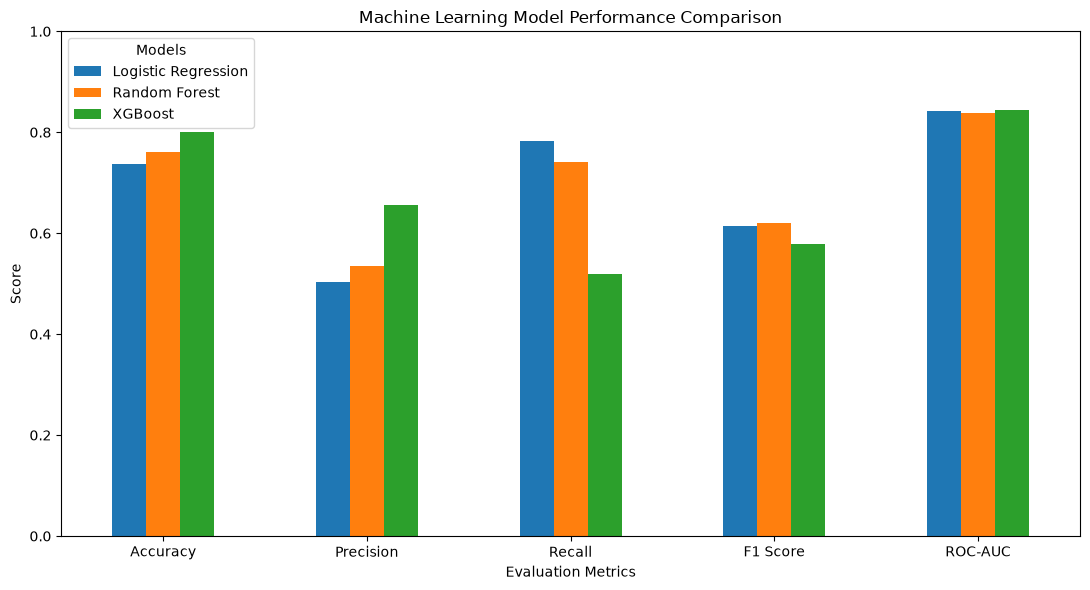

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Compare all three models
comparison_df = pd.DataFrame({
    "Logistic Regression": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred),
        roc_auc_score(y_test, lr_prob)
    ],

    "Random Forest": [
        accuracy_score(y_test, rf_pred),
        precision_score(y_test, rf_pred),
        recall_score(y_test, rf_pred),
        f1_score(y_test, rf_pred),
        roc_auc_score(y_test, rf_prob)
    ],

    "XGBoost": [
        accuracy_score(y_test, xgb_pred),
        precision_score(y_test, xgb_pred),
        recall_score(y_test, xgb_pred),
        f1_score(y_test, xgb_pred),
        roc_auc_score(y_test, xgb_prob)
    ]
}, index=["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"])

print(comparison_df.round(4))

# Plot comparison
comparison_df.plot(
    kind="bar",
    figsize=(11, 6),
    ylim=(0, 1)
)

plt.title("Machine Learning Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Evaluation Metrics")
plt.xticks(rotation=0)
plt.legend(title="Models")
plt.tight_layout()

plt.savefig(
    "../reports/figures/model_performance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [21]:
from sklearn.model_selection import train_test_split

X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Training Subset:", X_train_sub.shape)
print("Validation Set:", X_val.shape)

Training Subset: (4507, 19)
Validation Set: (1127, 19)


In [22]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

validation_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        ))
    ]
)

validation_model.fit(X_train_sub, y_train_sub)

print("Validation Model Training Completed!")

Validation Model Training Completed!


In [23]:
val_prob = validation_model.predict_proba(X_val)[:, 1]

print("First 10 Churn Probabilities:")
print(val_prob[:10])

First 10 Churn Probabilities:
[0.43245466 0.04801578 0.12892396 0.34576225 0.47849488 0.09534639
 0.40171198 0.04071179 0.0446263  0.46703658]


In [24]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

thresholds = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]

results = []

for threshold in thresholds:
    val_pred = (val_prob >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_val, val_pred),
        "Precision": precision_score(y_val, val_pred),
        "Recall": recall_score(y_val, val_pred),
        "F1 Score": f1_score(y_val, val_pred)
    })

threshold_results = pd.DataFrame(results)

print(threshold_results.round(4))

   Threshold  Accuracy  Precision  Recall  F1 Score
0       0.30    0.6460     0.4228  0.9164    0.5787
1       0.35    0.6664     0.4370  0.8930    0.5868
2       0.40    0.6992     0.4642  0.8662    0.6044
3       0.45    0.7276     0.4920  0.8261    0.6167
4       0.50    0.7542     0.5241  0.7993    0.6331
5       0.55    0.7684     0.5459  0.7559    0.6339
6       0.60    0.7826     0.5730  0.7090    0.6338


In [25]:
best_threshold = 0.55

print("Selected Threshold:", best_threshold)
print("Best Validation F1 Score:", 0.6339)

Selected Threshold: 0.55
Best Validation F1 Score: 0.6339


In [26]:
final_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        ))
    ]
)

final_model.fit(X_train, y_train)

print("Final Model Training Completed!")

Final Model Training Completed!


In [27]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Predict churn probabilities
test_prob = final_model.predict_proba(X_test)[:, 1]

# Apply selected threshold
final_pred = (test_prob >= best_threshold).astype(int)

print("Final Test Evaluation")
print("---------------------")
print("Threshold:", best_threshold)
print("Accuracy:", accuracy_score(y_test, final_pred))
print("Precision:", precision_score(y_test, final_pred))
print("Recall:", recall_score(y_test, final_pred))
print("F1 Score:", f1_score(y_test, final_pred))
print("ROC-AUC:", roc_auc_score(y_test, test_prob))

print("\nClassification Report:")
print(classification_report(
    y_test,
    final_pred,
    target_names=["Not Churn", "Churn"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, final_pred))

Final Test Evaluation
---------------------
Threshold: 0.55
Accuracy: 0.7530163236337828
Precision: 0.5242537313432836
Recall: 0.7513368983957219
F1 Score: 0.6175824175824176
ROC-AUC: 0.8416388953473353

Classification Report:
              precision    recall  f1-score   support

   Not Churn       0.89      0.75      0.82      1035
       Churn       0.52      0.75      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.80      0.75      0.76      1409

Confusion Matrix:
[[780 255]
 [ 93 281]]


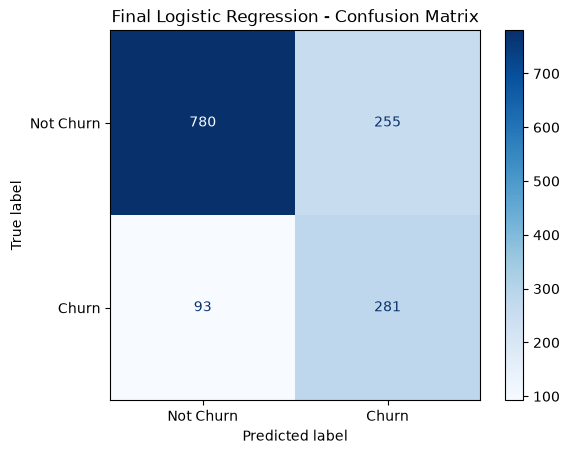

In [28]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_test, final_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Churn", "Churn"]
)

display.plot(cmap="Blues", values_format="d")

plt.title("Final Logistic Regression - Confusion Matrix")
plt.savefig(
    "../reports/figures/final_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [29]:
import joblib
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(final_model, "../models/customer_churn_model.pkl")

print("Final Model Saved Successfully!")
print("File: models/customer_churn_model.pkl")

Final Model Saved Successfully!
File: models/customer_churn_model.pkl


In [30]:
joblib.dump(best_threshold, "../models/churn_threshold.pkl")

print("Threshold Saved Successfully!")
print("Selected Threshold:", best_threshold)

Threshold Saved Successfully!
Selected Threshold: 0.55


In [31]:
# Extract feature names after preprocessing
feature_names = final_model.named_steps["preprocessor"].get_feature_names_out()

# Extract Logistic Regression coefficients
coefficients = final_model.named_steps["classifier"].coef_[0]

# Create feature importance DataFrame
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Sort by coefficient
feature_importance = feature_importance.sort_values(
    by="Coefficient",
    ascending=False
)

print("Top 10 Features Increasing Churn:")
print(feature_importance.head(10).round(4))

print("\nTop 10 Features Decreasing Churn:")
print(feature_importance.tail(10).sort_values(
    by="Coefficient"
).round(4))

Top 10 Features Increasing Churn:
                                Feature  Coefficient
16     cat__InternetService_Fiber optic       0.7080
36         cat__Contract_Month-to-month       0.6577
3                     num__TotalCharges       0.4897
35             cat__StreamingMovies_Yes       0.2754
32                 cat__StreamingTV_Yes       0.2622
43  cat__PaymentMethod_Electronic check       0.2403
18               cat__OnlineSecurity_No       0.1990
27                  cat__TechSupport_No       0.1655
14               cat__MultipleLines_Yes       0.1328
26            cat__DeviceProtection_Yes       0.0742

Top 10 Features Decreasing Churn:
                                      Feature  Coefficient
1                                 num__tenure      -1.1544
38                     cat__Contract_Two year      -0.7755
2                         num__MonthlyCharges      -0.6761
15                   cat__InternetService_DSL      -0.6225
31       cat__StreamingTV_No internet service      -0

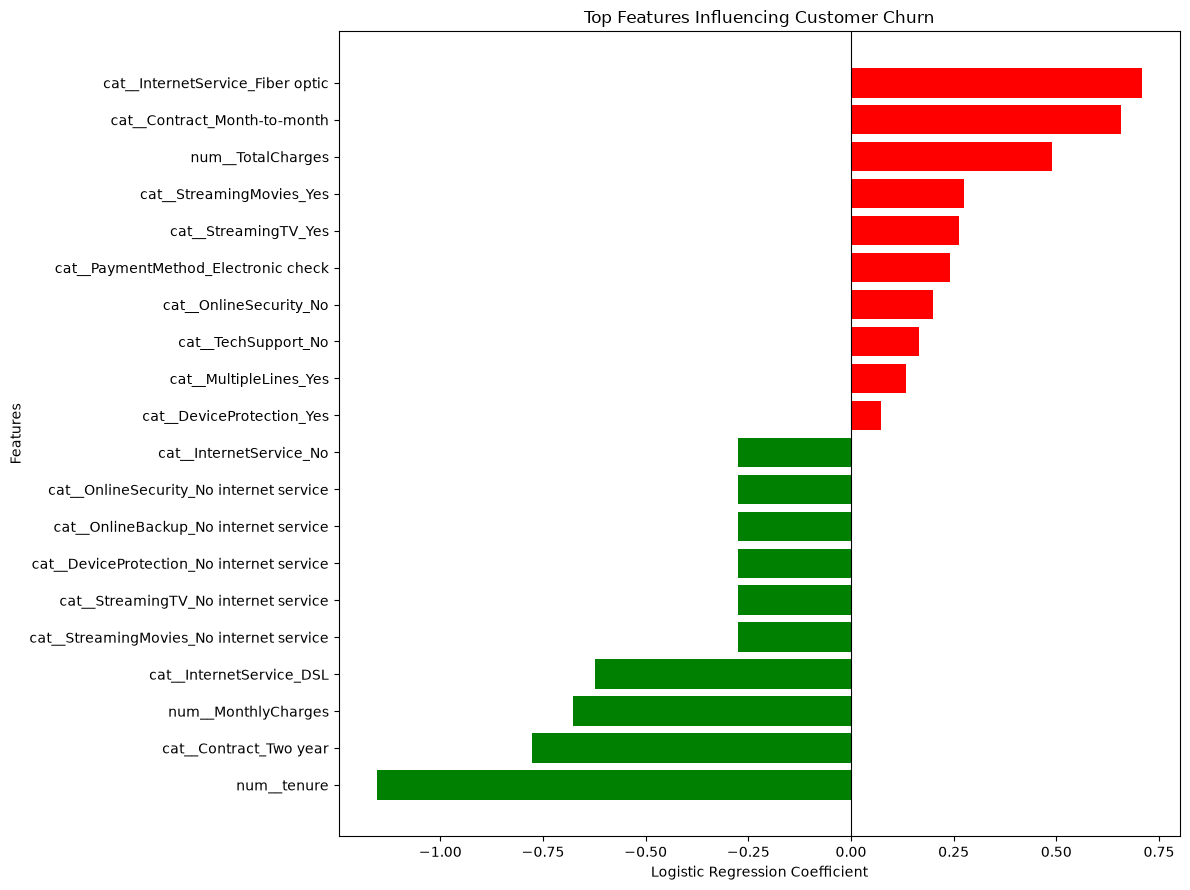

In [32]:
top_features = pd.concat([
    feature_importance.head(10),
    feature_importance.tail(10)
]).drop_duplicates()

top_features = top_features.sort_values(
    by="Coefficient"
)

plt.figure(figsize=(12, 9))

colors = [
    "red" if value > 0 else "green"
    for value in top_features["Coefficient"]
]

plt.barh(
    top_features["Feature"],
    top_features["Coefficient"],
    color=colors
)

plt.axvline(0, color="black", linewidth=0.8)

plt.title("Top Features Influencing Customer Churn")
plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Features")

plt.tight_layout()

plt.savefig(
    "../reports/figures/feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [33]:
import shap
from scipy import sparse

# Transform training and test data
X_train_transformed = final_model.named_steps["preprocessor"].transform(X_train)
X_test_transformed = final_model.named_steps["preprocessor"].transform(X_test)

# Convert sparse matrices to dense arrays if required
if sparse.issparse(X_train_transformed):
    X_train_transformed = X_train_transformed.toarray()

if sparse.issparse(X_test_transformed):
    X_test_transformed = X_test_transformed.toarray()

# Get transformed feature names
feature_names = final_model.named_steps["preprocessor"].get_feature_names_out()

print("SHAP Data Preparation Completed!")
print("Training Data:", X_train_transformed.shape)
print("Testing Data:", X_test_transformed.shape)
print("Features:", len(feature_names))

SHAP Data Preparation Completed!
Training Data: (5634, 45)
Testing Data: (1409, 45)
Features: 45


In [34]:
# Extract trained Logistic Regression classifier
classifier = final_model.named_steps["classifier"]

# Create SHAP Linear Explainer
explainer = shap.LinearExplainer(
    classifier,
    X_train_transformed
)

# Calculate SHAP values for test data
shap_values = explainer(X_test_transformed)

print("SHAP Values Calculated Successfully!")
print("SHAP Values Shape:", shap_values.values.shape)

Background dataset has 5634 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=5634 when initializing the masker.


SHAP Values Calculated Successfully!
SHAP Values Shape: (1409, 45)


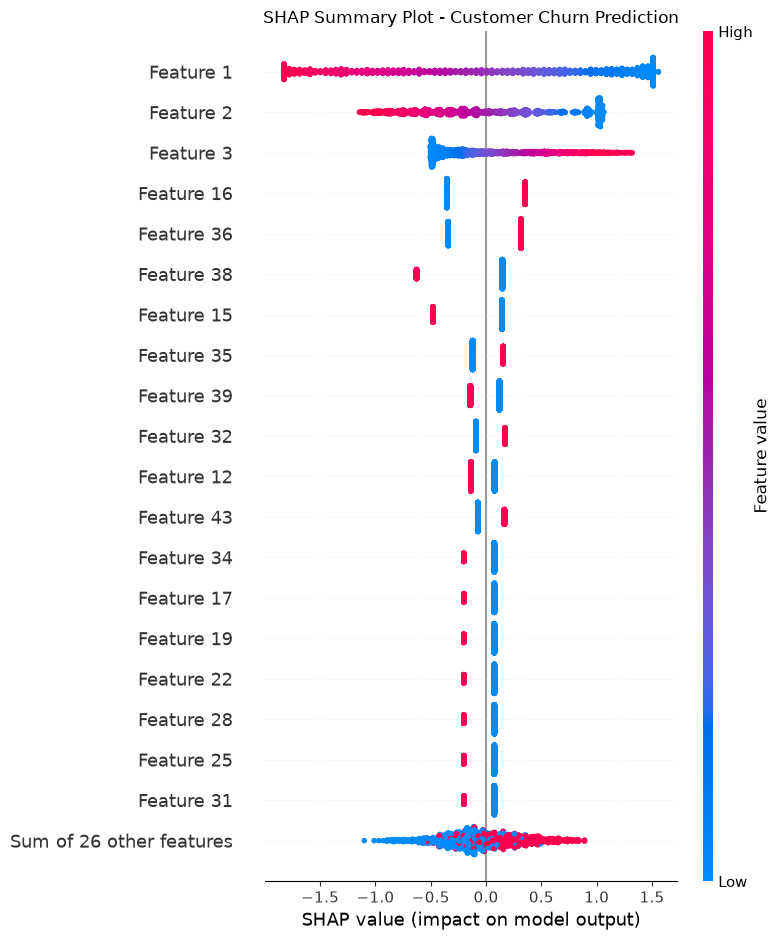

In [35]:
plt.figure(figsize=(12, 8))

shap.plots.beeswarm(
    shap_values,
    max_display=20,
    show=False
)

plt.title("SHAP Summary Plot - Customer Churn Prediction")

plt.tight_layout()

plt.savefig(
    "../reports/figures/shap_summary_plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

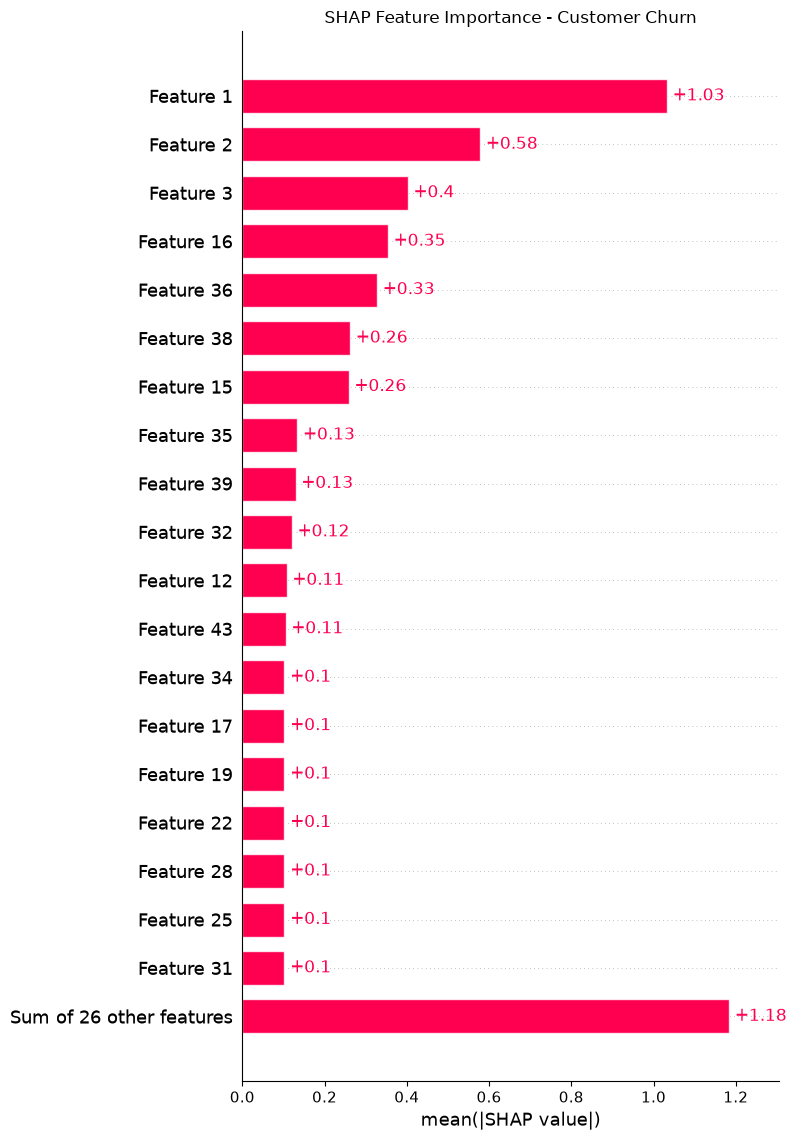

In [36]:
plt.figure(figsize=(12, 8))

shap.plots.bar(
    shap_values,
    max_display=20,
    show=False
)

plt.title("SHAP Feature Importance - Customer Churn")

plt.tight_layout()

plt.savefig(
    "../reports/figures/shap_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [37]:
# Load saved model and threshold
loaded_model = joblib.load("../models/customer_churn_model.pkl")
loaded_threshold = joblib.load("../models/churn_threshold.pkl")

# Predict one customer
sample_customer = X_test.iloc[[0]]

sample_probability = loaded_model.predict_proba(sample_customer)[0, 1]

sample_prediction = (
    "Churn" if sample_probability >= loaded_threshold
    else "Not Churn"
)

print("Saved Model Verification")
print("------------------------")
print("Churn Probability:", round(sample_probability, 4))
print("Selected Threshold:", loaded_threshold)
print("Prediction:", sample_prediction)

Saved Model Verification
------------------------
Churn Probability: 0.1177
Selected Threshold: 0.55
Prediction: Not Churn



# CHURNIQ – Customer Churn Exploratory Data Analysis

## 1. Project Overview

Customer churn refers to the situation where customers stop using a company's products or services.

This project analyzes customer data to identify patterns and factors associated with customer churn. The insights can help businesses understand customer behavior and develop effective retention strategies.

## 2. Business Problem

The objective is to analyze customer demographics, service subscriptions, contract types, tenure, and billing information to understand which customer groups have higher churn rates.

## 3. Dataset Information

- **Dataset:** IBM Telco Customer Churn
- **Total Records:** 7,043
- **Total Features:** 21
- **Target Variable:** Churn
- **Problem Type:** Binary Classification

## 4. Objectives

1. Understand the dataset structure and data quality.
2. Analyze overall customer churn distribution.
3. Identify churn patterns across contract types.
4. Explore the relationship between tenure and churn.
5. Analyze monthly charges and payment methods.
6. Identify important customer retention insights.

## 5. Tools and Technologies

Python, Pandas, NumPy, Matplotlib, Seaborn, Jupyter Notebook.
